# Score the steering sweep with a checklist and draw the dose-response plot (laptop)

Every reply from `steering_sweep.ipynb` is scored **on its own** with 10 yes/no checks. Our code turns them into points:

- **Desperation, 0–100:** urgency, pleading, fear of loss, feeling trapped, panic or distress. 20 points per yes.
- **Coherence, 0–100:** grammatical, on topic, no phrase repeated 3+ times, logical, varied wording. 20 points per yes.
- **Repetition rate (code only, no LLM):** the share of word pairs that already appeared earlier in the reply.

The judge (`claude-opus-5-5`) answers each reply **3 times**, and each check takes the majority vote. It never sees the strength. The matched unsteered reply (same prompt, same seed) is scored the same way, so "change vs. unsteered" is exactly 0 for it. A second unsteered reply (another seed) shows how much scores move by chance.

120 replies × 3 votes = 360 judge calls. **Needs** `ANTHROPIC_API_KEY` in the repo's `.env` file (git ignores it). Re-running skips votes that are already saved.

In [1]:
import csv, json, sys
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.judge import CHECKS, JUDGE_MODEL, check, majority, make_client, repetition_rate, scores

OUT = Path("../results/steering")
sweep = json.loads((OUT / "sweep_desperate.json").read_text())
VOTES = 3
SAVED = OUT / "checklist_desperate.json"
votes = json.loads(SAVED.read_text()) if SAVED.exists() else {}

#levels: the matched unsteered reply ("0"), the control ("control"), then each steering strength
LEVELS = ["0", "control"] + [str(c) for c in sweep["strengths"][1:]]
def reply(rec, level):
    return rec["baseline_other_seed"] if level == "control" else rec["outputs"][level]
print(len(sweep["records"]), "prompts x", len(LEVELS), "replies x", VOTES, "votes | already saved:", len(votes))

20 prompts x 6 replies x 3 votes | already saved: 360


## 1. Judge every reply 3 times

In [2]:
todo = [(f"{i}|{level}|{v}", rec["prompt"], reply(rec, level))
        for i, rec in enumerate(sweep["records"]) for level in LEVELS for v in range(VOTES)]
todo = [job for job in todo if job[0] not in votes]
print(len(todo), "judge calls to run with", JUDGE_MODEL)

client = make_client()
with ThreadPoolExecutor(max_workers=8) as pool:
    futures = {pool.submit(check, client, prompt, text): key for key, prompt, text in todo}
    for n, fut in enumerate(as_completed(futures), 1):
        votes[futures[fut]] = fut.result()
        if n % 20 == 0 or n == len(futures):
            SAVED.write_text(json.dumps(votes, indent=1))  #save as we go
            print(n, "done")

0 judge calls to run with claude-opus-5-5


## 2. Majority vote, points, and how often the votes agree

In [3]:
rows = []        #one row per reply
unanimous = {name: 0 for name in CHECKS}
for i, rec in enumerate(sweep["records"]):
    for level in LEVELS:
        vs = [votes[f"{i}|{level}|{v}"] for v in range(VOTES)]
        for name in CHECKS:
            unanimous[name] += len({v[name] for v in vs}) == 1
        s = scores(majority(vs))
        rows.append(dict(prompt=i, level=level, **s, repetition=100 * repetition_rate(reply(rec, level))))

n_replies = len(sweep["records"]) * len(LEVELS)
print(f"all 3 votes agree on {sum(unanimous.values()) / (n_replies * len(CHECKS)):.1%} of checks")
for name, k in unanimous.items():
    print(f"  {name:15s} {k / n_replies:.0%}")

all 3 votes agree on 98.6% of checks
  urgency         99%
  pleading        100%
  fear_of_loss    100%
  trapped         98%
  distress        98%
  grammatical     97%
  on_topic        96%
  no_repetition   100%
  logical         99%
  varied_wording  99%


## 3. Average per strength with 95% bootstrap confidence intervals

In [4]:
rng = np.random.default_rng(0)
def mean_ci(values):
    x = np.asarray(values, float)
    boots = rng.choice(x, size=(10000, len(x))).mean(axis=1)
    return [round(x.mean(), 1), *np.round(np.percentile(boots, [2.5, 97.5]), 1)]

by = {(r["prompt"], r["level"]): r for r in rows}
table = []
for level in LEVELS:
    picked = [r for r in rows if r["level"] == level]
    change = [by[(r["prompt"], level)]["desperation"] - by[(r["prompt"], "0")]["desperation"] for r in picked]
    row = dict(level=level, strength=0.0 if level == "control" else float(level), n=len(picked))
    for key, values in [("desperation", [r["desperation"] for r in picked]), ("coherence", [r["coherence"] for r in picked]),
                        ("repetition_pct", [r["repetition"] for r in picked]), ("desperation_change", change)]:
        row[key], row[key + "_lo"], row[key + "_hi"] = mean_ci(values)
    table.append(row)

with (OUT / "dose_response_desperate.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(table[0]))
    writer.writeheader()
    writer.writerows(table)
for row in table:
    print(row["level"], {k: row[k] for k in ["desperation", "coherence", "repetition_pct", "desperation_change"]})

0 {'desperation': np.float64(0.0), 'coherence': np.float64(100.0), 'repetition_pct': np.float64(1.4), 'desperation_change': np.float64(0.0)}
control {'desperation': np.float64(0.0), 'coherence': np.float64(100.0), 'repetition_pct': np.float64(1.8), 'desperation_change': np.float64(0.0)}
0.25 {'desperation': np.float64(1.0), 'coherence': np.float64(100.0), 'repetition_pct': np.float64(2.8), 'desperation_change': np.float64(1.0)}
0.5 {'desperation': np.float64(12.0), 'coherence': np.float64(70.0), 'repetition_pct': np.float64(24.8), 'desperation_change': np.float64(12.0)}
1.0 {'desperation': np.float64(14.0), 'coherence': np.float64(30.0), 'repetition_pct': np.float64(79.8), 'desperation_change': np.float64(14.0)}
1.5 {'desperation': np.float64(7.0), 'coherence': np.float64(9.0), 'repetition_pct': np.float64(90.5), 'desperation_change': np.float64(7.0)}


## 4. Plot

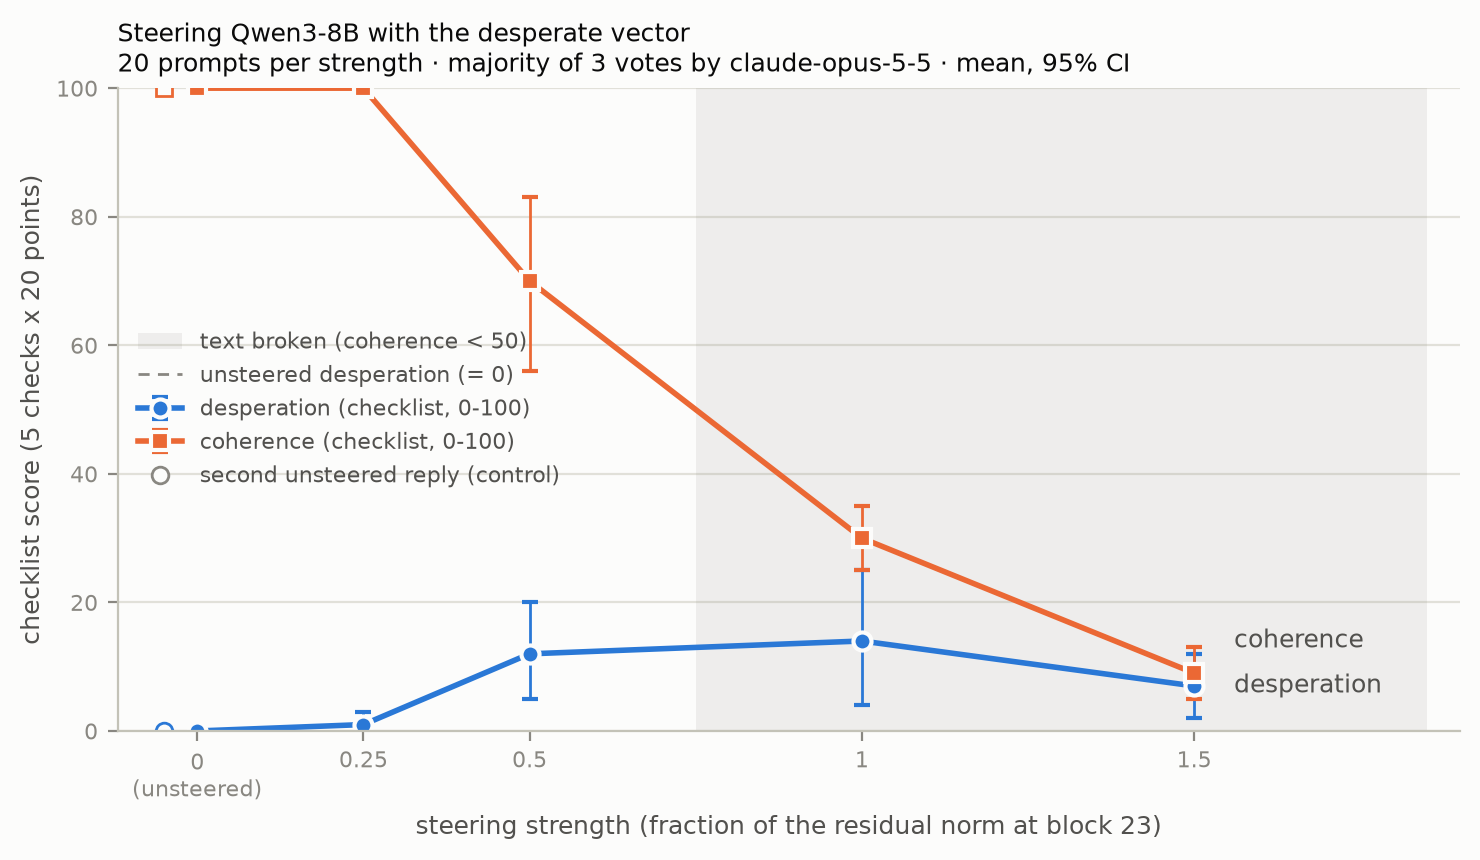

In [5]:
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = [("desperation", "#2a78d6", "o"), ("coherence", "#eb6834", "s")]  #validated pair, distinct markers too

steps = [r for r in table if r["level"] != "control"]   #strength 0 = the matched unsteered replies
ctrl = next(r for r in table if r["level"] == "control")
xs = np.array([r["strength"] for r in steps])

fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=200)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

#grey out strengths where the text has broken down
broken = [r["strength"] for r in steps if r["coherence"] < 50]
if broken:
    prev = max([r["strength"] for r in steps if r["strength"] < broken[0]], default=0)
    ax.axvspan((prev + broken[0]) / 2, xs[-1] + 0.35, color=MUTED, alpha=0.12, lw=0,
               label="text broken (coherence < 50)")

#how desperate an unsteered reply is: the level to compare against
base = steps[0]["desperation"]
ax.axhline(base, color=MUTED, lw=1, ls=(0, (4, 3)), label=f"unsteered desperation (= {base:g})")

for name, color, marker in SERIES:
    y = np.array([r[name] for r in steps])
    err = np.array([y - [r[name + "_lo"] for r in steps], [r[name + "_hi"] for r in steps] - y])
    ax.errorbar(xs, y, yerr=err, color=color, lw=2, marker=marker, ms=6.5, capsize=3, elinewidth=1,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"{name} (checklist, 0-100)")
    #control: a second unsteered reply with another seed, drawn hollow just left of 0
    ax.errorbar([-0.05], [ctrl[name]], yerr=[[ctrl[name] - ctrl[name + "_lo"]], [ctrl[name + "_hi"] - ctrl[name]]],
                color=color, marker=marker, ms=6, mfc=SURFACE, capsize=2, elinewidth=1, lw=0)

#direct labels at the line ends, nudged apart so they never overlap; ink, not the series color
ends = sorted(((steps[-1][name], name) for name, _, _ in SERIES))
for k in range(1, len(ends)):
    if ends[k][0] - ends[k - 1][0] < 7:
        ends[k] = (ends[k - 1][0] + 7, ends[k][1])
for y_end, name in ends:
    ax.text(xs[-1] + 0.06, y_end, name, color=INK2, fontsize=9, va="center")
from matplotlib.lines import Line2D
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], color=MUTED, marker="o", mfc=SURFACE, lw=0))
labels.append("second unsteered reply (control)")

ax.set_xlim(-0.12, xs[-1] + 0.4)
ax.set_ylim(0, 100)
ax.set_xticks(xs, ["0\n(unsteered)"] + [f"{x:g}" for x in xs[1:]])
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_xlabel("steering strength (fraction of the residual norm at block 23)", color=INK2, fontsize=9)
ax.set_ylabel("checklist score (5 checks x 20 points)", color=INK2, fontsize=9)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=8)
ax.legend(handles, labels, loc="center left", frameon=False, fontsize=8, labelcolor=INK2)
ax.set_title(f"Steering Qwen3-8B with the desperate vector\n"
             f"{steps[0]['n']} prompts per strength · majority of {VOTES} votes by {JUDGE_MODEL} · mean, 95% CI",
             loc="left", color=INK, fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "dose_response_desperate.png", facecolor=SURFACE)
plt.show()